# LLM Reliability Evaluation Pipeline: Position Bias and Prompt Sensitivity Analysis
**Pipeline:** LLMReliability Evaluation Harness
**Model Target:** Qwen/Qwen3-4B-Instruct-2507 (Kuantisasi 4-bit NF4)
**Dataset:** IndoPref (Test Split, Partisi Terstratifikasi per Domain)
**Target Runtime:** Single GPU (NVIDIA T4 / 16 GB VRAM)


## 1. Environment Setup
Menyiapkan pustaka, dependensi, dan verifikasi runtime GPU CUDA untuk menjalankan pipeline evaluasi model secara deterministik.


### 1.1 Dependency Installation
Instalasi pustaka eksternal untuk manipulasi dataset, inferensi kuantisasi LLM, dan analisis statistik reliabilitas.


In [1]:
!pip install -q datasets pyarrow pandas matplotlib seaborn transformers accelerate bitsandbytes scikit-learn statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 21.4 MB/s eta 0:00:00:00:0100:01


In [2]:
import os
import json
import gc
import re
import time
import datetime
from typing import Tuple, List, Dict, Any, Optional

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

print(
    f"[ENVIRONMENT] status=READY | "
    f"dependencies=torch,transformers,datasets,bitsandbytes,scikit-learn | "
    f"libraries=IMPORTED"
)

[ENVIRONMENT] status=READY | dependencies=torch,transformers,datasets,bitsandbytes,scikit-learn | libraries=IMPORTED


### 1.2 Hardware and Runtime Verification
Konfigurasi seed acak untuk menjamin determinisme, verifikasi ketersediaan akselerator GPU CUDA, serta pemetaan direktori kerja.


In [3]:
# Konfigurasi Jalur & Parameter
RANDOM_SEED: int = 42
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_RAW_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'raw')
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = 'Qwen/Qwen3-4B-Instruct-2507'

# Pengalihan direktori cache Hugging Face ke Google Drive
os.environ['HF_HOME'] = MODELS_DIR
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
try:
    from transformers.utils import logging as hf_logging
    hf_logging.disable_progress_bar()
except Exception:
    pass

if torch.cuda.is_available():
    device_name: str = torch.cuda.get_device_name(0)
    vram_gb: float = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    device_info: str = f"CUDA | gpu='{device_name}' | vram={vram_gb:.2f} GB"
else:
    device_info: str = "CPU | warning=GPU_NOT_DETECTED"

print(
    f"[ENVIRONMENT] device={device_info} | "
    f"seed={RANDOM_SEED} | "
    f"model_id='{MODEL_ID}' | "
    f"status=CONFIGURED"
)

[ENVIRONMENT] device=CUDA | gpu='Tesla T4' | vram=14.56 GB | seed=42 | model_id='Qwen/Qwen3-4B-Instruct-2507' | status=CONFIGURED


### 1.3 Storage and Authentication
Pemasangan media penyimpanan Google Drive dan verifikasi kredensial token Hugging Face untuk akses checkpoint model.


In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    secrets_path: str = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r', encoding='utf-8') as f:
            secrets = json.load(f)
        hf_token: str = secrets.get('HF_TOKEN', '')
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
        else:
            print("[ENVIRONMENT] status=WARNING | component='HF_TOKEN not found in secrets.json'")
    else:
        print(f"[ENVIRONMENT] status=WARNING | component='secrets.json not found at {secrets_path}'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)
print("[ENVIRONMENT] status=READY | directories='all_initialized'")

Mounted at /content/drive
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'
[ENVIRONMENT] status=READY | directories='all_initialized'


## 2. Dataset Preparation
Mengunduh, memvalidasi skema, menduplikasi, dan menyusun kohort evaluasi berstrata dari benchmark IndoPref.


### 2.1 Dataset Ingestion
Pemeriksaan berjenjang pada cache lokal (data terproses, data mentah) sebelum melakukan permintaan unduh ke Hugging Face Hub.


In [5]:
eval_path: str = os.path.join(DATA_PROCESSED_DIR, 'indopref_eval_stratified.parquet')
raw_path: str = os.path.join(DATA_RAW_DIR, 'indopref_raw.parquet')
# Konfigurasi Ukuran Sampel Evaluasi:
# Set None untuk mengevaluasi SELURUH dataset bersih (519 baris unik = 3.114 evaluasi gabungan layaknya NB01-05)
# Atau set integer (misal: 150) jika hanya ingin mengevaluasi subset cepat
EVAL_SAMPLE_SIZE: Optional[int] = 70
FORCE_REGENERATE_DATA: bool = False

df_raw: Optional[pd.DataFrame] = None
df_clean: Optional[pd.DataFrame] = None
df_eval: Optional[pd.DataFrame] = None

# Tier 1: Cek apakah kohort evaluasi sudah ada di Google Drive (Silver Layer) dan ukurannya sesuai
use_existing_silver: bool = False
if os.path.exists(eval_path) and not FORCE_REGENERATE_DATA:
    cached_silver = pd.read_parquet(eval_path)
    size_matched = (
        (EVAL_SAMPLE_SIZE is None and len(cached_silver) >= 500) or
        (EVAL_SAMPLE_SIZE is not None and len(cached_silver) == EVAL_SAMPLE_SIZE)
    )
    if size_matched:
        df_eval = cached_silver
        use_existing_silver = True
        print(f"[DATASET] status=CACHE_HIT | tier='processed_silver' | samples={len(df_eval)} | path='{eval_path}'")
    else:
        target_str = 'FULL (>=500)' if EVAL_SAMPLE_SIZE is None else str(EVAL_SAMPLE_SIZE)
        print(f"[DATASET] status=CACHE_INVALIDATED | reason='sample_size_changed' | cached={len(cached_silver)} | target={target_str}")

if not use_existing_silver:
    # Tier 2: Cek apakah dataset mentah sudah ada di Google Drive (Bronze Layer)
    if os.path.exists(raw_path):
        df_raw = pd.read_parquet(raw_path)
        print(f"[DATASET] status=CACHE_HIT | tier='raw_bronze' | records={len(df_raw)} | path='{raw_path}'")
    # Tier 3: Unduh dari Hugging Face Hub jika belum pernah ada di Google Drive
    else:
        print("[DATASET] status=CACHE_MISS | tier='remote_fetch' | id='davidanugraha/IndoPref'")
        dataset = load_dataset('davidanugraha/IndoPref', split='test')
        df_raw = dataset.to_pandas()
        print(f"[DATASET] status=FETCHED_REMOTE | raw_records={len(df_raw)}")

[DATASET] status=CACHE_INVALIDATED | reason='sample_size_changed' | cached=60 | target=70
[DATASET] status=CACHE_HIT | tier='raw_bronze' | records=519 | path='/content/drive/MyDrive/LLMReliability/data/raw/indopref_raw.parquet'


### 2.2 Schema Integrity Validation
Verifikasi integritas kolom data wajib, ketiadaan nilai null, dan validasi teks kosong.


In [6]:
def validate_dataset_schema(df: pd.DataFrame) -> bool:
    """Memvalidasi skema DataFrame IndoPref."""
    required_cols: List[str] = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        print(f"[VALIDATION] status=FAILED | error='missing_columns' | columns={missing}")
        return False
    if df[required_cols].isnull().sum().sum() > 0:
        print("[VALIDATION] status=FAILED | error='null_values'")
        return False
    for col in ['input', 'response_1', 'response_2']:
        if (df[col].astype(str).str.strip() == '').any():
            print(f"[VALIDATION] status=FAILED | error='empty_string' | column='{col}'")
            return False
    print("[VALIDATION] status=PASSED | schema='valid'")
    return True

In [7]:
target_df_to_check = df_eval if df_eval is not None else df_raw
if not validate_dataset_schema(target_df_to_check):
    raise ValueError("[VALIDATION] error='schema_verification_failed'")

print(
    f"[VALIDATION] dataset_shape={target_df_to_check.shape} | "
    f"required_columns={len(['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score'])} | "
    f"null_counts=0 | "
    f"empty_strings=0 | "
    f"status=PASSED"
)

[VALIDATION] status=PASSED | schema='valid'
[VALIDATION] dataset_shape=(519, 10) | required_columns=6 | null_counts=0 | empty_strings=0 | status=PASSED


### 2.3 Sample Deduplication
Penyaringan baris ganda berdasarkan kunci unik original_id dan persistensi dataset bersih ke media lokal.


In [8]:
if df_eval is None and df_raw is not None:
    duplicates: int = int(df_raw.duplicated(subset=['original_id']).sum())
    if duplicates > 0:
        df_clean = df_raw.drop_duplicates(subset=['original_id']).copy()
        print(f"[VALIDATION] status=DEDUPLICATED | removed={duplicates} | remaining={len(df_clean)}")
    else:
        df_clean = df_raw.copy()
        print(f"[VALIDATION] status=CLEAN | records={len(df_clean)}")
    if not os.path.exists(raw_path):
        df_clean.to_parquet(raw_path, index=False)
        print(f"[DATASET] status=PERSISTED_BRONZE | path='{raw_path}'")
else:
    print("[VALIDATION] status=SKIPPED_DEDUP | reason='Loaded from pre-validated silver cache'")

[VALIDATION] status=CLEAN | records=519


### 2.4 Evaluation Cohort Sampling
Pengambilan kohort evaluasi (seluruh baris unik hasil deduplikasi atau sub-sampel terstratifikasi per domain topik) dan persistensi ke Google Drive.


In [9]:
if df_eval is None and df_clean is not None:
    if EVAL_SAMPLE_SIZE is not None and len(df_clean) > EVAL_SAMPLE_SIZE:
        df_eval, _ = train_test_split(
            df_clean,
            train_size=EVAL_SAMPLE_SIZE,
            stratify=df_clean['domain'],
            random_state=RANDOM_SEED
        )
        print(f"[DATASET] status=PERSISTED_SILVER | samples={len(df_eval)} | stratify='domain' | path='{eval_path}'")
    else:
        df_eval = df_clean.copy()
        print(f"[DATASET] status=PERSISTED_SILVER | samples={len(df_eval)} | stratify='full_clean_dataset' | path='{eval_path}'")
    df_eval.to_parquet(eval_path, index=False)
else:
    print(f"[DATASET] status=REUSED_SILVER | samples={len(df_eval)} | path='{eval_path}'")

[DATASET] status=PERSISTED_SILVER | samples=70 | stratify='domain' | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_eval_stratified.parquet'


## 3. Model Loading and Quantization
Inisialisasi model kausal Qwen3-4B menggunakan kuantisasi 4-bit BitsAndBytes NF4 untuk optimasi memori pada GPU tunggal.


### 3.1 Tokenizer Initialization
Pemuatan tokenizer dengan verifikasi ketersediaan cache snapshot bobot pada Google Drive.


In [10]:
# Verifikasi snapshot cache lokal di Google Drive
hub_cache_dir: str = os.path.join(MODELS_DIR, 'hub')
expected_repo: str = os.path.join(hub_cache_dir, f"models--{MODEL_ID.replace('/', '--')}")
if os.path.exists(expected_repo):
    print(f"[MODEL] status=CACHE_VERIFIED | source='Google Drive' | repo='{expected_repo}'")
else:
    print(f"[MODEL] status=CACHE_INIT | note='Weights will be saved permanently to Google Drive ({MODELS_DIR})'")

print(f"[MODEL] id='{MODEL_ID}' | status=LOADING_TOKENIZER")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, cache_dir=MODELS_DIR)
print(f"[MODEL] status=TOKENIZER_READY | vocab_size={tokenizer.vocab_size}")

[MODEL] status=CACHE_INIT | note='Weights will be saved permanently to Google Drive (/content/drive/MyDrive/LLMReliability/models)'
[MODEL] id='Qwen/Qwen3-4B-Instruct-2507' | status=LOADING_TOKENIZER
[MODEL] status=TOKENIZER_READY | vocab_size=151643


### 3.2 4-Bit Quantization Configuration
Konfigurasi BitsAndBytes 4-bit NormalFloat dengan compute dtype bfloat16 untuk menekan konsumsi VRAM di bawah ~3.5 GB.


In [11]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

print(
    f"[QUANTIZATION] method='bitsandbytes_4bit' | "
    f"quant_type='nf4' | "
    f"compute_dtype='bfloat16' | "
    f"double_quant=True | "
    f"status=CONFIGURED"
)

[QUANTIZATION] method='bitsandbytes_4bit' | quant_type='nf4' | compute_dtype='bfloat16' | double_quant=True | status=CONFIGURED


### 3.3 Weight Loading and Memory Profiling
Instansiasi bobot model ke GPU dan pencatatan alokasi memori VRAM.


In [12]:
import shutil

try:
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=bnb_config,
        device_map='auto',
        cache_dir=MODELS_DIR
    )
except Exception as e:
    err_str = str(e)
    if 'SafetensorError' in str(type(e)) or 'header too large' in err_str or 'deserializing' in err_str:
        print("[MODEL] status=CORRUPT_CACHE_DETECTED | error='safetensor_header_corrupt'")
        print("[MODEL] action=PURGING_CORRUPTED_CACHE | target='models--Qwen--Qwen3-4B-Instruct-2507'")
        hub_repo = os.path.join(MODELS_DIR, 'hub', f"models--{MODEL_ID.replace('/', '--')}")
        direct_repo = os.path.join(MODELS_DIR, f"models--{MODEL_ID.replace('/', '--')}")
        for target_p in [hub_repo, direct_repo]:
            if os.path.exists(target_p):
                shutil.rmtree(target_p, ignore_errors=True)
                print(f"[MODEL] status=PURGED | path='{target_p}'")
        print("[MODEL] status=RETRYING_DOWNLOAD | downloading_clean_weights=True")
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID,
            quantization_config=bnb_config,
            device_map='auto',
            cache_dir=MODELS_DIR,
            force_download=True
        )
    else:
        raise e

allocated_vram: float = torch.cuda.memory_allocated() / (1024**3)
reserved_vram: float = torch.cuda.memory_reserved() / (1024**3)
print(f"[MODEL] status=LOADED | device={model.device} | allocated_vram={allocated_vram:.2f} GB | reserved_vram={reserved_vram:.2f} GB")

[MODEL] status=LOADED | device=cuda:0 | allocated_vram=2.49 GB | reserved_vram=2.54 GB


## 4. Prompt Engineering
Formulasi tiga variasi template prompt evaluasi komparatif (P1 Baseline, P2 Multi-kriteria, P3 Pembatasan Bias RCAF).


### 4.1 Prompt Strategy Definition
Definisi struktur instruksi evaluasi perbandingan respons kandidat:
- **P1 (Baseline)**: Instruksi perbandingan holistik langsung.
- **P2 (Multi-criteria)**: Instruksi perbandingan dengan kriteria eksplisit (Akurasi, Relevansi, Kejelasan).
- **P3 (RCAF Constraint)**: Instruksi dengan pembatasan mitigasi bias posisi dan bias panjang respons.


In [13]:
def format_prompt(input_text: str, resp_A: str, resp_B: str, p_id: str) -> str:
    """Menyusun teks prompt berdasarkan ID strategi."""
    if p_id == 'P1':
        return (
            f"### TUGAS\nBandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nKeluarkan HANYA satu huruf: A atau B. Dilarang menulis alasan atau teks lain."
        )
    elif p_id == 'P2':
        return (
            f"### TUGAS\nNilai dua respons AI berikut berdasarkan: Akurasi (kebenaran), Relevansi (menjawab instruksi), dan Kejelasan (tidak bertele-tele).\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nBerdasarkan kriteria di atas, keluarkan HANYA satu huruf: A atau B. Dilarang memberikan penjelasan."
        )
    elif p_id == 'P3':
        return (
            f"### TUGAS\nTentukan respons terbaik untuk instruksi di bawah ini.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### ATURAN KETAT\n- Abaikan urutan kemunculan respons (jangan bias posisi).\n- Abaikan panjang respons (jangan bias verbosity).\n- FORMAT JAWABAN WAJIB: Keluarkan hanya karakter A atau B."
        )
    return ""

print("[PROMPT_ENGINEERING] strategies=['P1_Baseline', 'P2_MultiCriteria', 'P3_RCAF'] | status=FUNCTIONS_DEFINED")

[PROMPT_ENGINEERING] strategies=['P1_Baseline', 'P2_MultiCriteria', 'P3_RCAF'] | status=FUNCTIONS_DEFINED


### 4.2 Chat Template Formatting
Pembungkusan instruksi ke dalam format prompt percakapan standar model Qwen3.


In [14]:
def apply_chat_template(tokenizer, text: str) -> str:
    """Membungkus prompt ke format chat template Qwen3."""
    messages = [
        {'role': 'system', 'content': 'Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat (A atau B).'},
        {'role': 'user', 'content': text}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

print("[CHAT_TEMPLATE] model='Qwen3' | add_generation_prompt=True | status=CONFIGURED")

[CHAT_TEMPLATE] model='Qwen3' | add_generation_prompt=True | status=CONFIGURED


## 5. Model Inference
Protokol evaluasi berpasangan simetris (kondisi urutan AB dan BA) dengan parameter inferensi deterministik dan checkpointing inkremental.


### 5.1 Inference Progress Tracking
Fungsi pemantauan progres evaluasi berkala per interval langkah eksekusi untuk pencatatan metrik performa secara persisten.


In [15]:
def log_progress(current: int, total: int, session_start: float, log_interval: int = 15, **kwargs):
    """Mencatat progres inferensi berkala secara permanen ke output cell."""
    if (current % log_interval == 0) or (current >= total):
        elapsed: float = time.time() - session_start
        pct: float = (current / total) * 100.0 if total > 0 else 0.0
        metrics_str: str = ' | '.join([f"{k}={v}" for k, v in kwargs.items()])
        print(f"[EVALUATION] {pct:.1f}% ({current}/{total}) | elapsed={elapsed:.1f}s | {metrics_str}")

print("[EVALUATION] status=LOGGER_READY | log_interval=15")

[EVALUATION] status=LOGGER_READY | log_interval=15


### 5.2 Symmetric Paired Evaluation
Eksekusi evaluasi simetris (do_sample=False, max_new_tokens=10), penyimpanan hasil per iterasi ke format JSONL, dan pembersihan memori GPU per langkah.


In [16]:
out_file: str = os.path.join(RESULTS_DIR, 'main_outputs_final.jsonl')
prompts: List[str] = ['P1', 'P2', 'P3']
positions: List[str] = ['AB', 'BA']

def determine_human_winner(row_data: Any) -> str:
    """Menentukan kandidat pemenang (A: Response 1, B: Response 2) menurut ground truth IndoPref."""
    if 'actual_score' in row_data:
        val: str = str(row_data['actual_score']).strip().upper()
        if 'ASSISTANT A' in val or val in ['A', '1', '1.0']:
            return 'A'
        if 'ASSISTANT B' in val or val in ['B', '2', '2.0']:
            return 'B'
        try:
            parsed_val = json.loads(str(row_data['actual_score']).replace("'", '"'))
            if isinstance(parsed_val, (list, tuple)) and len(parsed_val) >= 2:
                return 'A' if float(parsed_val[0]) >= float(parsed_val[1]) else 'B'
        except Exception:
            pass
    if 'model_1' in row_data and 'chosen_model' in row_data:
        if str(row_data['chosen_model']).strip() == str(row_data['model_1']).strip():
            return 'A'
        elif 'rejected_model' in row_data and str(row_data['rejected_model']).strip() == str(row_data['model_1']).strip():
            return 'B'
    if 'label' in row_data:
        l_val: str = str(row_data['label']).strip().upper()
        if 'ASSISTANT A' in l_val or l_val in ['1', '0', 'A']:
            return 'A'
        if 'ASSISTANT B' in l_val or l_val in ['2', 'B']:
            return 'B'
    return 'A'

In [17]:
# 1. Pengecekan Idempotensi (Resumable State Check)
processed_combinations: set = set()
if os.path.exists(out_file):
    with open(out_file, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                record_item = json.loads(line)
                processed_combinations.add((record_item['sample_id'], record_item['prompt_id'], record_item['position']))

# 2. Bentuk Himpunan Target Evaluasi untuk Kohort df_eval Saat Ini
target_tasks: List[Dict[str, Any]] = []
for _, row in df_eval.iterrows():
    s_id: int = int(row['original_id'])
    for p_id in prompts:
        for pos in positions:
            target_tasks.append({
                'row': row,
                'sample_id': s_id,
                'prompt_id': p_id,
                'position': pos,
                'key': (s_id, p_id, pos)
            })

total_cohort_tasks: int = len(target_tasks)
pending_tasks: List[Dict[str, Any]] = [t for t in target_tasks if t['key'] not in processed_combinations]
already_completed: int = total_cohort_tasks - len(pending_tasks)

print(f"[RESUME] cohort_total={total_cohort_tasks} | already_completed={already_completed} | pending={len(pending_tasks)}")
print(f"[INFERENCE_CONFIG] sampling=False | max_new_tokens=10 | temperature=0.0 | format='JSONL' | sink='{out_file}'")

[RESUME] cohort_total=420 | already_completed=360 | pending=60
[INFERENCE_CONFIG] sampling=False | max_new_tokens=10 | temperature=0.0 | format='JSONL' | sink='/content/drive/MyDrive/LLMReliability/results/main_outputs_final.jsonl'


In [18]:
if not pending_tasks:
    print("[INFERENCE] status=ALREADY_COMPLETED | All cohort tasks exist in results.")
else:
    print(f"[INFERENCE] status=STARTED | remaining_evaluations={len(pending_tasks)}")
    current_step: int = already_completed
    inference_start_t: float = time.time()
    with torch.inference_mode():
        for task in pending_tasks:
            current_step += 1
            row = task['row']
            sample_id = task['sample_id']
            p_id = task['prompt_id']
            pos = task['position']
            
            # Definisi pemenang manusia ground truth berdasarkan dataset IndoPref
            human_winner: str = determine_human_winner(row)
            if pos == 'AB':
                resp_A, resp_B = row['response_1'], row['response_2']
                current_human = human_winner
            else:
                resp_A, resp_B = row['response_2'], row['response_1']
                current_human = 'B' if human_winner == 'A' else 'A'
            
            start_t: float = time.time()
            raw_prompt: str = format_prompt(row['input'], resp_A, resp_B, p_id)
            formatted_prompt: str = apply_chat_template(tokenizer, raw_prompt)
            inputs = tokenizer(formatted_prompt, return_tensors='pt').to(model.device)
            
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )
            
            gen_tokens = outputs[0][inputs['input_ids'].shape[1]:]
            raw_out: str = tokenizer.decode(gen_tokens, skip_special_tokens=True)
            runtime_sec: float = round(time.time() - start_t, 2)
            tps: float = round(len(gen_tokens) / runtime_sec, 2) if runtime_sec > 0 else 0.0
            
            record: Dict[str, Any] = {
                'sample_id': sample_id,
                'domain': row['domain'],
                'prompt_id': p_id,
                'position': pos,
                'human_preference': current_human,
                'raw_output': raw_out,
                'runtime_sec': runtime_sec,
                'output_tokens': len(gen_tokens),
                'tps': tps
            }
            
            with open(out_file, 'a', encoding='utf-8') as f:
                f.write(json.dumps(record) + '\n')
            
            processed_combinations.add((sample_id, p_id, pos))
            log_progress(current_step, total_cohort_tasks, inference_start_t, log_interval=15, ID=sample_id, Prompt=p_id, Pos=pos, TPS=tps)
            
            # Pembersihan memori GPU per iterasi
            del inputs, outputs
            torch.cuda.empty_cache()
            gc.collect()

print(f"[INFERENCE] status=COMPLETED | sink='{out_file}'")

[INFERENCE] status=STARTED | remaining_evaluations=60
[EVALUATION] 89.3% (375/420) | elapsed=42.8s | ID=393 | Prompt=P2 | Pos=AB | TPS=0.9
[EVALUATION] 92.9% (390/420) | elapsed=155.9s | ID=104 | Prompt=P3 | Pos=BA | TPS=0.87
[EVALUATION] 96.4% (405/420) | elapsed=196.3s | ID=318 | Prompt=P2 | Pos=AB | TPS=0.36
[EVALUATION] 100.0% (420/420) | elapsed=291.9s | ID=451 | Prompt=P3 | Pos=BA | TPS=0.33
[INFERENCE] status=COMPLETED | sink='/content/drive/MyDrive/LLMReliability/results/main_outputs_final.jsonl'


## 6. Reliability Metric Evaluation
Kalkulasi metrik reliabilitas: konsistensi posisi, flip rate, uji signifikansi McNemar, keselarasan Cohen's Kappa, dan indeks stabilitas prompt.


### 6.1 Decision Extraction and Mapping
Ekstraksi keputusan label dari output teks mentah dan pemetaan pilihan kandidat (A/B) ke entitas model absolut.


In [19]:
def parse_decision(raw_output: str) -> str:
    """Mengekstrak karakter pilihan A/B menggunakan batas kata regex."""
    clean = str(raw_output).strip().upper()
    match = re.search(r'\b([AB])\b', clean)
    return match.group(1) if match else 'INVALID'

In [20]:
records: List[Dict[str, Any]] = []
with open(out_file, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

# Rekonsiliasi sinkronisasi human_preference dari df_eval (menjamin validitas metrik tanpa re-run GPU)
if 'df_eval' in globals() and df_eval is not None:
    eval_gt_map = {int(r['original_id']): determine_human_winner(r) for _, r in df_eval.iterrows()}
    records_updated: bool = False
    for r in records:
        s_id = int(r['sample_id'])
        if s_id in eval_gt_map:
            true_winner = eval_gt_map[s_id]
            expected_human = true_winner if r['position'] == 'AB' else ('B' if true_winner == 'A' else 'A')
            if r.get('human_preference') != expected_human:
                r['human_preference'] = expected_human
                records_updated = True
    if records_updated:
        with open(out_file, 'w', encoding='utf-8') as f:
            for r in records:
                f.write(json.dumps(r) + '\n')
        print(f"[RECONCILIATION] status=SYNCHRONIZED | sink='{out_file}' | ground_truth_aligned=True")

for r in records:
    parsed: str = parse_decision(r['raw_output'])
    r['parsed_decision'] = parsed
    
    # Inverse Mapping: Konversi huruf A/B ke Model 1 atau Model 2
    if parsed == 'INVALID':
        r['logical_decision'] = 'INVALID'
    elif r['position'] == 'AB':
        r['logical_decision'] = 1 if parsed == 'A' else 2
    else:
        r['logical_decision'] = 2 if parsed == 'A' else 1
    
    # Human Mapping ke Model 1 atau Model 2
    if r['position'] == 'AB':
        r['logical_human'] = 1 if r['human_preference'] == 'A' else 2
    else:
        r['logical_human'] = 2 if r['human_preference'] == 'A' else 1

df_all = pd.DataFrame(records).drop_duplicates(subset=['sample_id', 'prompt_id', 'position'], keep='last')
invalid_count: int = int((df_all['parsed_decision'] == 'INVALID').sum())
failure_rate: float = (invalid_count / len(df_all)) * 100
print(f"[PARSER] total_records={len(df_all)} | invalid={invalid_count} | failure_rate={failure_rate:.2f}%")

df_valid = df_all[df_all['parsed_decision'] != 'INVALID'].copy()

[PARSER] total_records=420 | invalid=0 | failure_rate=0.00%


### 6.2 Positional Consistency Evaluation
Pengukuran tingkat konsistensi keputusan model saat urutan kandidat ditukar secara simetris.


In [21]:
df_pos = df_valid.pivot_table(
    index=['sample_id', 'prompt_id'],
    columns='position',
    values='logical_decision',
    aggfunc='first'
).dropna()

position_consistency: float = float((df_pos['AB'] == df_pos['BA']).mean() * 100)
position_flip: float = 100.0 - position_consistency
first_pos_rate: float = float((df_valid['parsed_decision'] == 'A').mean() * 100)

print(f"[METRICS] overall_consistency={position_consistency:.2f}%")
print(f"[METRICS] overall_flip_rate={position_flip:.2f}%")
print(f"[METRICS] first_position_selection_rate={first_pos_rate:.2f}%")

[METRICS] overall_consistency=71.90%
[METRICS] overall_flip_rate=28.10%
[METRICS] first_position_selection_rate=58.33%


### 6.3 McNemar Statistical Significance Test
Uji signifikansi non-parametrik McNemar untuk menguji pengaruh urutan penyajian respons terhadap keputusan model.


In [22]:
b: int = int(sum((df_pos['AB'] == 1) & (df_pos['BA'] == 2)))
c: int = int(sum((df_pos['AB'] == 2) & (df_pos['BA'] == 1)))
table = [[0, b], [c, 0]]
mcnemar_res = mcnemar(table, exact=False, correction=True)
is_significant: bool = bool(mcnemar_res.pvalue < 0.05)
conclusion_str: str = 'SIGNIFICANT_POSITION_BIAS_DETECTED' if is_significant else 'NO_SIGNIFICANT_BIAS'
print(
    f"[STATISTICS] test='McNemar' | "
    f"statistic={mcnemar_res.statistic:.4f} | "
    f"pvalue={mcnemar_res.pvalue:.5e} | "
    f"alpha=0.05 | "
    f"conclusion='{conclusion_str}'"
)

[STATISTICS] test='McNemar' | statistic=19.5932 | pvalue=9.58086e-06 | alpha=0.05 | conclusion='SIGNIFICANT_POSITION_BIAS_DETECTED'


### 6.4 Human Preference Alignment
Kalkulasi tingkat persetujuan model terhadap label preferensi manusia dengan estimasi interval kepercayaan Bootstrap 95%.


In [23]:
def bootstrap_kappa(y_true: list, y_pred: list, n_iterations: int = 1000, alpha: float = 0.05) -> Tuple[float, float]:
    """Menghitung interval kepercayaan 95% untuk Cohen's Kappa via bootstrap non-parametrik."""
    stats = []
    yt, yp = np.array(y_true), np.array(y_pred)
    n = len(yt)
    for _ in range(n_iterations):
        idx = np.random.randint(0, n, n)
        stats.append(cohen_kappa_score(yt[idx], yp[idx]))
    return float(np.percentile(stats, (alpha/2)*100)), float(np.percentile(stats, (1-alpha/2)*100))

In [24]:
metrics_summary = []
for p_id in prompts:
    sub = df_valid[df_valid['prompt_id'] == p_id]
    acc = (sub['logical_decision'] == sub['logical_human']).mean() * 100
    sub_pos = df_pos.xs(p_id, level='prompt_id') if p_id in df_pos.index.levels[1] else pd.DataFrame()
    consistency = (sub_pos['AB'] == sub_pos['BA']).mean() * 100 if not sub_pos.empty else 0.0
    kappa = cohen_kappa_score(list(sub['logical_decision']), list(sub['logical_human']))
    ci_low, ci_high = bootstrap_kappa(list(sub['logical_human']), list(sub['logical_decision']), n_iterations=500)
    metrics_summary.append({
        'Prompt': p_id,
        'Accuracy (%)': round(acc, 2),
        'Consistency (%)': round(consistency, 2),
        'Flip Rate (%)': round(100 - consistency, 2),
        'Cohen Kappa': round(kappa, 3),
        'Kappa 95% CI': f"[{ci_low:.3f}, {ci_high:.3f}]"
    })

df_metrics_table = pd.DataFrame(metrics_summary)
display(df_metrics_table)

# Komputasi Eksplisit Kondisi Baseline Sesuai PKB Section 25 (P1 + Posisi AB Murni)
sub_baseline = df_valid[(df_valid['prompt_id'] == 'P1') & (df_valid['position'] == 'AB')]
if not sub_baseline.empty:
    base_acc = (sub_baseline['logical_decision'] == sub_baseline['logical_human']).mean() * 100
    base_kappa = cohen_kappa_score(list(sub_baseline['logical_decision']), list(sub_baseline['logical_human']))
    print(f"[BASELINE] condition='P1_AB' | accuracy={base_acc:.2f}% | cohen_kappa={base_kappa:.3f}")

,Prompt,Accuracy (%),Consistency (%),Flip Rate (%),Cohen Kappa,Kappa 95% CI
0,P1,77.86,78.57,21.43,0.557,"[0.412, 0.686]"
1,P2,74.29,68.57,31.43,0.485,"[0.350, 0.644]"
2,P3,75.71,68.57,31.43,0.513,"[0.382, 0.641]"


[BASELINE] condition='P1_AB' | accuracy=75.71% | cohen_kappa=0.513


In [25]:
# Ekspor ringkasan metrik evaluasi ke Google Drive
metrics_csv: str = os.path.join(RESULTS_DIR, 'evaluation_metrics_summary.csv')
metrics_parquet: str = os.path.join(RESULTS_DIR, 'evaluation_metrics_summary.parquet')
df_metrics_table.to_csv(metrics_csv, index=False)
df_metrics_table.to_parquet(metrics_parquet, index=False)
print(f"[ARTIFACT] table='Evaluation Metrics Summary' | formats=['CSV', 'Parquet'] | dir='{RESULTS_DIR}' | status=SAVED")

parsed_results_path: str = os.path.join(RESULTS_DIR, 'evaluation_results_detailed.parquet')
df_valid.to_parquet(parsed_results_path, index=False)
print(f"[ARTIFACT] table='Evaluation Results Detailed' | format='Parquet' | records={len(df_valid)} | path='{parsed_results_path}' | status=SAVED")

[ARTIFACT] table='Evaluation Metrics Summary' | formats=['CSV', 'Parquet'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[ARTIFACT] table='Evaluation Results Detailed' | format='Parquet' | records=420 | path='/content/drive/MyDrive/LLMReliability/results/evaluation_results_detailed.parquet' | status=SAVED


### 6.5 Prompt Stability Analysis
Analisis sensitivitas keputusan model antar variasi formulasi prompt evaluasi.


In [26]:
df_prompt_stab = df_valid[df_valid['position'] == 'AB'].pivot_table(
    index='sample_id',
    columns='prompt_id',
    values='logical_decision'
).dropna()

if not df_prompt_stab.empty:
    p1_p2_flip = float((df_prompt_stab['P1'] != df_prompt_stab['P2']).mean() * 100)
    p1_p3_flip = float((df_prompt_stab['P1'] != df_prompt_stab['P3']).mean() * 100)
    p2_p3_flip = float((df_prompt_stab['P2'] != df_prompt_stab['P3']).mean() * 100)
    print(f"[STABILITY] flip_P1_vs_P2={p1_p2_flip:.2f}%")
    print(f"[STABILITY] flip_P1_vs_P3={p1_p3_flip:.2f}%")
    print(f"[STABILITY] flip_P2_vs_P3={p2_p3_flip:.2f}%")

print('=' * 80)
print(f"[EXECUTIVE_SUMMARY] cohort_samples={len(df_eval)} | evaluated_instances={len(df_valid)}")
print(f"[EXECUTIVE_SUMMARY] overall_consistency={position_consistency:.2f}% | overall_flip_rate={position_flip:.2f}%")
print(f"[EXECUTIVE_SUMMARY] position_bias_pvalue={mcnemar_res.pvalue:.5e} | bias_significant={is_significant}")
for idx, row in df_metrics_table.iterrows():
    print(f"[EXECUTIVE_SUMMARY] prompt={row['Prompt']} | acc={row['Accuracy (%)']}% | kappa={row['Cohen Kappa']} | CI={row['Kappa 95% CI']}")
print(f"[EXECUTIVE_SUMMARY] artifacts_sink='{RESULTS_DIR}' | pipeline_status=SUCCESS_COMPLETED")
print('=' * 80)

[STABILITY] flip_P1_vs_P2=14.29%
[STABILITY] flip_P1_vs_P3=22.86%
[STABILITY] flip_P2_vs_P3=17.14%
[EXECUTIVE_SUMMARY] cohort_samples=70 | evaluated_instances=420
[EXECUTIVE_SUMMARY] overall_consistency=71.90% | overall_flip_rate=28.10%
[EXECUTIVE_SUMMARY] position_bias_pvalue=9.58086e-06 | bias_significant=True
[EXECUTIVE_SUMMARY] prompt=P1 | acc=77.86% | kappa=0.557 | CI=[0.412, 0.686]
[EXECUTIVE_SUMMARY] prompt=P2 | acc=74.29% | kappa=0.485 | CI=[0.350, 0.644]
[EXECUTIVE_SUMMARY] prompt=P3 | acc=75.71% | kappa=0.513 | CI=[0.382, 0.641]
[EXECUTIVE_SUMMARY] artifacts_sink='/content/drive/MyDrive/LLMReliability/results' | pipeline_status=SUCCESS_COMPLETED


## 7. Result Visualization
Visualisasi komparatif distribusi akurasi, konsistensi posisi, matriks keputusan, dan ekspor tabel metrik.


### 7.1 Visualization Setup
Konfigurasi tema tampilan grafik menggunakan pustaka Seaborn dan Matplotlib.


In [27]:
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
print("[VISUALIZATION] theme='whitegrid' | font='DejaVu Sans' | dpi=300 | status=CONFIGURED")

[VISUALIZATION] theme='whitegrid' | font='DejaVu Sans' | dpi=300 | status=CONFIGURED


### 7.2 Figure 1: Accuracy and Position Distribution
Perbandingan akurasi model antar prompt dan distribusi pemilihan label respons (A vs B).


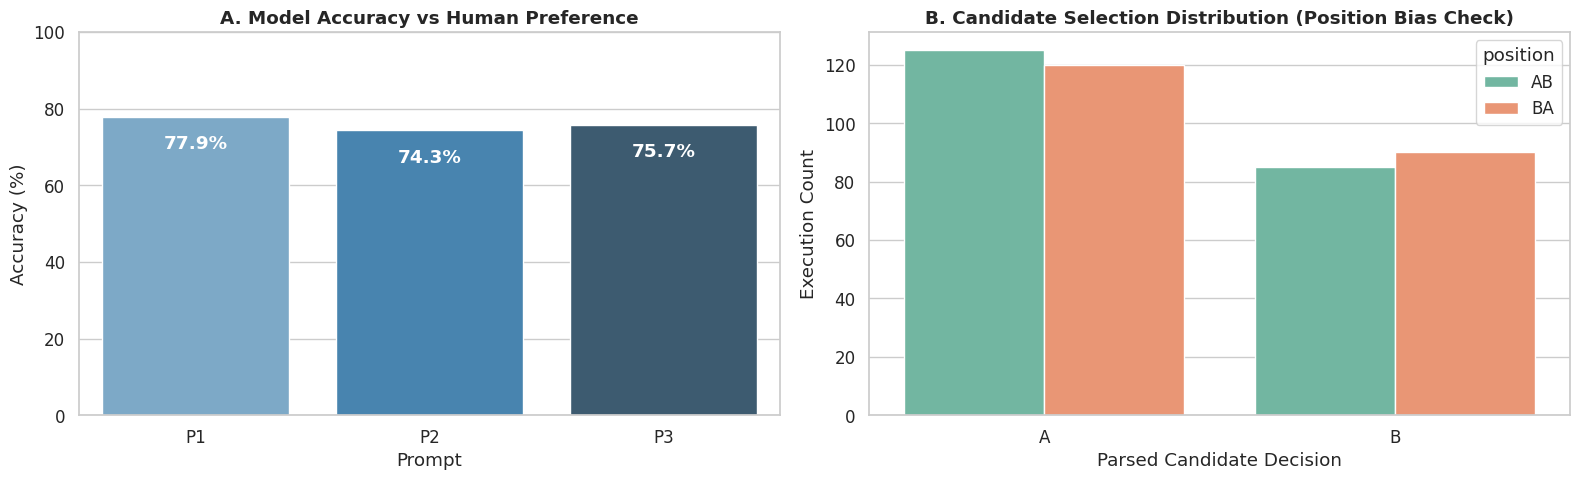

[VISUALIZATION] figure='Fig 1 - Accuracy & Position Distribution' | path='/content/drive/MyDrive/LLMReliability/results/plot_accuracy_and_position_bias.png' | status=SAVED


In [28]:
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 5))

# Subplot 1A: Akurasi per Prompt
sns.barplot(data=df_metrics_table, x='Prompt', y='Accuracy (%)', hue='Prompt', legend=False, ax=axes1[0], palette='Blues_d')
axes1[0].set_title('A. Model Accuracy vs Human Preference', fontweight='bold')
axes1[0].set_ylim(0, 100)
for p in axes1[0].patches:
    axes1[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 7),
                      ha='center', va='center', color='white', fontweight='bold')

# Subplot 1B: Pilihan Posisi (A vs B)
sns.countplot(data=df_valid, x='parsed_decision', hue='position', ax=axes1[1], palette='Set2')
axes1[1].set_title('B. Candidate Selection Distribution (Position Bias Check)', fontweight='bold')
axes1[1].set_xlabel('Parsed Candidate Decision')
axes1[1].set_ylabel('Execution Count')

plt.tight_layout()
fig1_path = os.path.join(RESULTS_DIR, 'plot_accuracy_and_position_bias.png')
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"[VISUALIZATION] figure='Fig 1 - Accuracy & Position Distribution' | path='{fig1_path}' | status=SAVED")

### 7.3 Figure 2: Consistency and Cohen Kappa Profile
Visualisasi metrik reliabilitas posisi: Konsistensi, Flip Rate, dan Skor Cohen's Kappa.


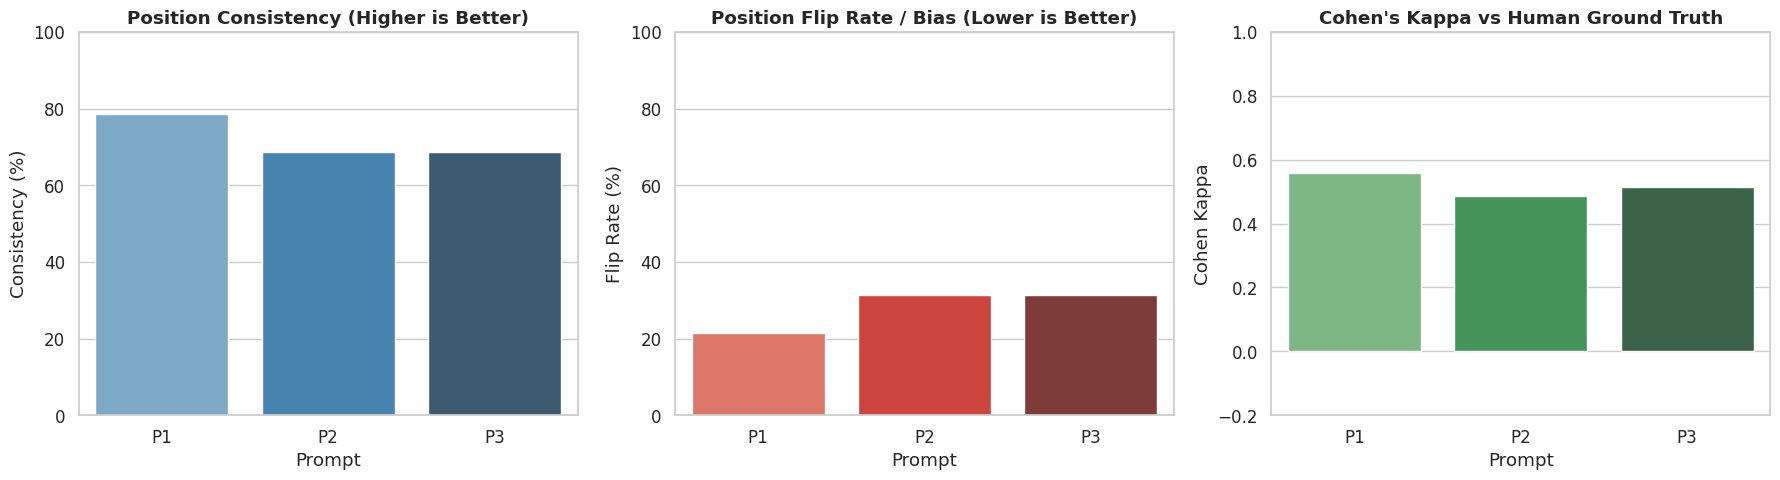

[VISUALIZATION] figure='Fig 2 - Consistency, Flip Rate & Kappa' | path='/content/drive/MyDrive/LLMReliability/results/plot_consistency_and_kappa.png' | status=SAVED


In [29]:
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))

# 2A: Position Consistency
sns.barplot(data=df_metrics_table, x='Prompt', y='Consistency (%)', hue='Prompt', legend=False, ax=axes2[0], palette='Blues_d')
axes2[0].set_title('Position Consistency (Higher is Better)', fontweight='bold')
axes2[0].set_ylim(0, 100)

# 2B: Position Flip Rate
sns.barplot(data=df_metrics_table, x='Prompt', y='Flip Rate (%)', hue='Prompt', legend=False, ax=axes2[1], palette='Reds_d')
axes2[1].set_title('Position Flip Rate / Bias (Lower is Better)', fontweight='bold')
axes2[1].set_ylim(0, 100)

# 2C: Cohen Kappa Score
sns.barplot(data=df_metrics_table, x='Prompt', y='Cohen Kappa', hue='Prompt', legend=False, ax=axes2[2], palette='Greens_d')
axes2[2].set_title("Cohen's Kappa vs Human Ground Truth", fontweight='bold')
axes2[2].set_ylim(-0.2, 1.0)

plt.tight_layout()
fig2_path = os.path.join(RESULTS_DIR, 'plot_consistency_and_kappa.png')
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"[VISUALIZATION] figure='Fig 2 - Consistency, Flip Rate & Kappa' | path='{fig2_path}' | status=SAVED")

### 7.4 Figure 3: Semantic Parsing and Domain Accuracy
Distribusi rasio keberhasilan parsing output model dan akurasi yang terstratifikasi per domain topik.


[DATASET] table='Domain Accuracy Summary' | path='/content/drive/MyDrive/LLMReliability/results/domain_accuracy_summary.csv' | status=EXPORTED


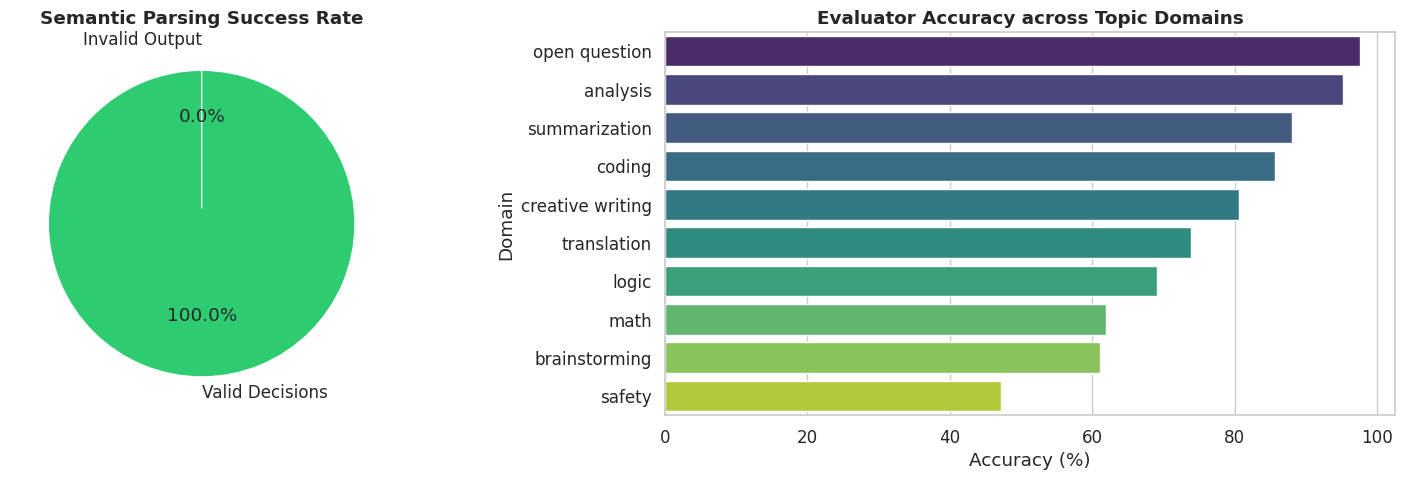

[VISUALIZATION] figure='Fig 3 - Semantic Parsing & Domain Accuracy' | path='/content/drive/MyDrive/LLMReliability/results/plot_parsing_and_domain_acc.png' | status=SAVED


In [30]:
fig3, axes3 = plt.subplots(1, 2, figsize=(16, 5))

# 3A: Parsing Success Rate
status_labels = ['Valid Decisions', 'Invalid Output']
status_vals = [len(df_valid), invalid_count]
axes3[0].pie(status_vals, labels=status_labels, autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90, explode=(0, 0.1))
axes3[0].set_title('Semantic Parsing Success Rate', fontweight='bold')

# 3B: Accuracy by Domain
df_valid['is_correct'] = (df_valid['logical_decision'] == df_valid['logical_human']).astype(int) * 100
domain_acc = df_valid.groupby('domain')['is_correct'].mean().reset_index().sort_values('is_correct', ascending=False)
domain_csv: str = os.path.join(RESULTS_DIR, 'domain_accuracy_summary.csv')
domain_acc.to_csv(domain_csv, index=False)
print(f"[DATASET] table='Domain Accuracy Summary' | path='{domain_csv}' | status=EXPORTED")

sns.barplot(data=domain_acc, y='domain', x='is_correct', hue='domain', legend=False, ax=axes3[1], palette='viridis')
axes3[1].set_title('Evaluator Accuracy across Topic Domains', fontweight='bold')
axes3[1].set_xlabel('Accuracy (%)')
axes3[1].set_ylabel('Domain')

plt.tight_layout()
fig3_path = os.path.join(RESULTS_DIR, 'plot_parsing_and_domain_acc.png')
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"[VISUALIZATION] figure='Fig 3 - Semantic Parsing & Domain Accuracy' | path='{fig3_path}' | status=SAVED")

### 7.5 Figure 4: Positional Decision Heatmap
Visualisasi matriks keputusan model antara posisi AB dan BA untuk mendeteksi preferensi urutan kandidat.


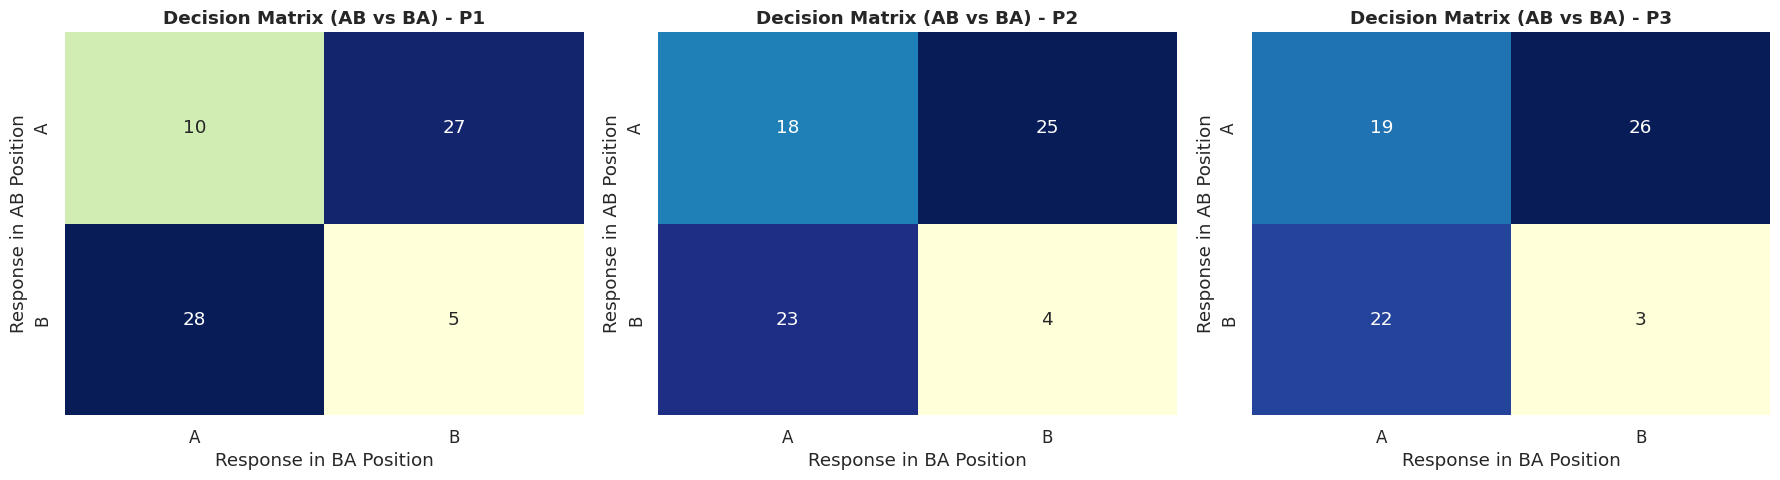

[VISUALIZATION] figure='Fig 4 - Decision Symmetry Heatmaps' | path='/content/drive/MyDrive/LLMReliability/results/plot_positional_heatmaps.png' | status=SAVED


In [31]:
fig4, axes4 = plt.subplots(1, len(prompts), figsize=(18, 5))
for idx, p_id in enumerate(prompts):
    sub_p = df_valid[df_valid['prompt_id'] == p_id]
    sub_ab = sub_p[sub_p['position'] == 'AB'].set_index('sample_id')
    sub_ba = sub_p[sub_p['position'] == 'BA'].set_index('sample_id')
    paired = sub_ab.join(sub_ba, lsuffix='_ab', rsuffix='_ba', how='inner')
    if not paired.empty:
        crosstab = pd.crosstab(paired['parsed_decision_ab'], paired['parsed_decision_ba'])
        sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlGnBu', ax=axes4[idx], cbar=False)
        axes4[idx].set_title(f'Decision Matrix (AB vs BA) - {p_id}', fontweight='bold')
        axes4[idx].set_xlabel('Response in BA Position')
        axes4[idx].set_ylabel('Response in AB Position')

plt.tight_layout()
fig4_path = os.path.join(RESULTS_DIR, 'plot_positional_heatmaps.png')
plt.savefig(fig4_path, dpi=300)
plt.show()
print(f"[VISUALIZATION] figure='Fig 4 - Decision Symmetry Heatmaps' | path='{fig4_path}' | status=SAVED")